# Etapa 9. Servicio y Visualización (Trie, Top-K y Dashboard Interactivo)

Proyecto EDA 2026-2 · Grupo 1 · Escenario B (comercio electrónico)

Esta etapa materializa la capa de servicio de cara al usuario final y unifica de manera observable las diez etapas del pipeline. Implementa:

1. **Autocompletado de prefijos en tiempo real:** Estructura de árbol de prefijos (**Trie**) con caché local Top-K precomputada en cada nodo, garantizando latencias constantes $O(L)$ de nivel sub-milisegundo.
2. **Ranking Top-K multicriterio con MinHeap acotado:** Algoritmo de selección asintóticamente óptimo en $O(N \log K)$ frente al ordenamiento completo $O(N \log N)$, combinando similitud vectorial de atributos (Etapa 7 HNSW), similitud de comportamiento (Etapa 7 MinHash + LSH), autoridad espectral (Etapa 8 PageRank) y afinidad de co-compra (Etapa 8 CSR).
3. **Monitoreo de seguridad y fraude:** Integración del panel de alertas probabilísticas de la Etapa 6 (Bloom Filter + Count-Min Sketch).
4. **Dashboard y visualización interactiva:** Interfaz web completa disponible en `visualizador/dashboard_servicio.html`.


## Paso 1. Configuración y entrada

Se configuran las rutas del proyecto, la semilla determinista (`SEED = 42`) y la detección de plataforma.


In [1]:
import gc
import json
import os
import platform
import sys
import time
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Raíz del proyecto
RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
    os.chdir(RAIZ)
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.etapa_9.service import (
    IndiceInvertido,
    NodoTrie,
    ScoringHibrido,
    ServicioEcommerce,
    TopKHeap,
    Trie,
    ejecutar_etapa,
    normalizar_texto,
    tokenizar,
)

CATEGORIA = "Office_Products"
DIR_INTERIM = RAIZ / "data" / "interim" / CATEGORIA
DIR_ETAPA9 = DIR_INTERIM / "etapa_9"
DIR_RESULTADOS = RAIZ / "results" / "etapa_9"

SEED = 42
PLATAFORMA = {
    "procesador": platform.processor() or platform.machine(),
    "python": platform.python_version(),
    "sistema": platform.system(),
}
print("Entorno configurado:", PLATAFORMA)


Entorno configurado: {'procesador': 'arm', 'python': '3.12.13', 'sistema': 'Darwin'}


## Paso 2. Estructura de Datos Trie (Árbol de Prefijos)

El **Trie** (Fredkin, 1960) organiza el vocabulario del catálogo estructurado como un árbol donde cada arista representa un carácter. 

**Optimización de latencia con Top-K Caché Local:**
En un Trie estándar, resolver un prefijo de longitud $L$ requiere descender hasta el nodo del prefijo en $O(L)$ y luego recorrer exhaustivamente el subárbol descendente para encontrar las mejores palabras ($O(L + |\text{subárbol}| \log K)$). Para garantizar respuesta instantánea (*search-as-you-type*), cada nodo mantiene una caché local con las $M$ sugerencias de mayor frecuencia que transitan por él, reduciendo la complejidad de consulta estrictamente a $O(L)$, independiente del tamaño del vocabulario.


In [2]:
# 2.1 Demostración de Trie con Top-K Caché
trie_demo = Trie(capacidad_cache=5)

# Insertar términos con frecuencias de popularidad
terminos_muestra = [
    ("toner brother tn436", 500.0, {"asin": "B0BF98LWMZ", "cat": "Toner"}),
    ("toner hp laserjet", 420.0, {"asin": "B01F3M964Y", "cat": "Toner"}),
    ("toner canon imageclass", 310.0, {"asin": "B00DY8P67W", "cat": "Toner"}),
    ("tinta epson ecotank", 290.0, {"asin": "B07KPL8Q91", "cat": "Tinta"}),
    ("tijeras de oficina scotch", 180.0, {"asin": "B00006IE5D", "cat": "Papelería"}),
    ("papel bond 500 hojas", 400.0, {"asin": "B001PMHZZ6", "cat": "Papel"}),
    ("papel fotográfico glossy", 150.0, {"asin": "B09MHP71BG", "cat": "Papel"}),
]

for term, freq, meta in terminos_muestra:
    trie_demo.insertar(term, frecuencia=freq, meta=meta)

print(f"Términos indexados en Trie demo: {len(trie_demo)}")

# Consultar prefijo 'ton'
sugerencias_ton = trie_demo.autocompletar("ton", k=3)
print("\nSugerencias de autocompletado para prefijo 'ton':")
display(pd.DataFrame(sugerencias_ton))

# Consultar prefijo 'pap'
sugerencias_pap = trie_demo.autocompletar("pap", k=3)
print("\nSugerencias de autocompletado para prefijo 'pap':")
display(pd.DataFrame(sugerencias_pap))


Términos indexados en Trie demo: 7

Sugerencias de autocompletado para prefijo 'ton':


,termino,frecuencia,meta
0,toner brother tn436,500.0,"{'asin': 'B0BF98LWMZ', 'cat': 'Toner'}"
1,toner hp laserjet,420.0,"{'asin': 'B01F3M964Y', 'cat': 'Toner'}"
2,toner canon imageclass,310.0,"{'asin': 'B00DY8P67W', 'cat': 'Toner'}"



Sugerencias de autocompletado para prefijo 'pap':


,termino,frecuencia,meta
0,papel bond 500 hojas,400.0,"{'asin': 'B001PMHZZ6', 'cat': 'Papel'}"
1,papel fotográfico glossy,150.0,"{'asin': 'B09MHP71BG', 'cat': 'Papel'}"


## Paso 3. Estructura de Datos Top-K con MinHeap

Para clasificar los $K$ mejores productos entre $N$ candidatos:
- Ordenar la lista completa con `sorted()` cuesta $O(N \log N)$ tiempo y $O(N)$ espacio.
- La estructura **TopKHeap** mantiene un `MinHeap` de tamaño acotado $K$. Al evaluar cada candidato con score $s$:
  - Si el heap tiene menos de $K$ elementos, se inserta en $O(\log K)$.
  - Si ya contiene $K$ elementos y $s > \text{raíz.score}$, se reemplaza la raíz en $O(\log K)$.
  - De lo contrario, se descarta en $O(1)$.
- Complejidad total: **$O(N \log K)$** en tiempo y **$O(K)$** en espacio auxiliar. Cuando $N = 10^6$ y $K = 10$, $N \log K \approx 3.3 \times 10^6$ operaciones frente a $N \log N \approx 20 \times 10^6$ de un ordenamiento completo, logrando una aceleración de más de 3×.


In [3]:
# 3.1 Demostración de TopKHeap
topk_demo = TopKHeap(k=3)
candidatos_demo = [
    ("Producto Alfa", 0.42),
    ("Producto Beta", 0.89),
    ("Producto Gamma", 0.15),
    ("Producto Delta", 0.96),
    ("Producto Epsilon", 0.73),
]

for item, score in candidatos_demo:
    topk_demo.agregar(item, score)

print("Top 3 elementos seleccionados:")
for score, item in topk_demo.obtener_top():
    print(f"  Score: {score:.2f} -> {item}")


Top 3 elementos seleccionados:
  Score: 0.96 -> Producto Delta
  Score: 0.89 -> Producto Beta
  Score: 0.73 -> Producto Epsilon


## Paso 4. Función de Scoring Híbrido Multicriterio

La relevancia de un producto complementario $p$ respecto a una consulta o producto base $q$ se calcula mediante una combinación lineal convexa de cuatro dimensiones del pipeline:

$$S(p \mid q) = w_{\text{sim}} \cdot S_{\text{sim}}(p, q) + w_{\text{rel}} \cdot S_{\text{rel}}(p, q) + w_{\text{pr}} \cdot \widetilde{S}_{\text{pr}}(p) + w_{\text{co}} \cdot S_{\text{co}}(p, q)$$

donde:
- $S_{\text{sim}}(p, q) = \max(0, 1 - d_{\text{HNSW}}(p, q))$: Similitud de atributos textuales y categoría (Etapa 7).
- $S_{\text{rel}}(p, q) = J(p, q)$: Co-ocurrencia de usuarios estimada por MinHash + LSH (Etapa 7).
- $\widetilde{S}_{\text{pr}}(p) = \frac{\text{PageRank}(p)}{\max \text{PageRank}}$: Autoridad espectral global en el grafo (Etapa 8).
- $S_{\text{co}}(p, q) = \frac{w_{pq}}{\max_k w_{pk}}$: Afinidad directa de co-compra en la matriz CSR (Etapa 8).
- Ponderación calibrada: $w_{\text{sim}} = 0.35, w_{\text{rel}} = 0.25, w_{\text{pr}} = 0.20, w_{\text{co}} = 0.20$.


In [4]:
# 4.1 Evaluación de Scoring Híbrido
scoring = ScoringHibrido(
    peso_similitud=0.35,
    peso_relacionados=0.25,
    peso_pagerank=0.20,
    peso_cocompra=0.20,
)

s1 = scoring.calcular_score(similitud_atributos=0.85, jaccard_comportamiento=0.12, pagerank_normalizado=0.90, afinidad_cocompra=0.75)
s2 = scoring.calcular_score(similitud_atributos=0.30, jaccard_comportamiento=0.01, pagerank_normalizado=0.10, afinidad_cocompra=0.00)

print(f"Score Producto Relevante y Conectado: {s1:.4f}")
print(f"Score Producto Poco Relacionado:      {s2:.4f}")


Score Producto Relevante y Conectado: 0.6575
Score Producto Poco Relacionado:      0.1275


## Paso 5. Orquestación del Servicio de Comercio Electrónico

La clase `ServicioEcommerce` integra los artefactos generados en las etapas 3, 6, 7 y 8, proporcionando una API unificada en memoria principal.


In [5]:
# 5.1 Carga del Servicio
servicio = ServicioEcommerce(RAIZ / "data" / "interim", categoria=CATEGORIA)
servicio.cargar_datos()  # catálogo completo (antes 50 000 inserciones, ~3 % del catálogo)

print(f"Términos en Trie: {len(servicio.trie):,}")
print(f"Productos con PageRank: {len(servicio._pagerank):,}")
print(f"Productos con Similares HNSW: {len(servicio._similares):,}")
print(f"Productos con Relacionados LSH: {len(servicio._relacionados):,}")


ServicioEcommerce inicializado en 32.67 s
Términos en Trie: 585,983
Productos con PageRank: 150,534
Productos con Similares HNSW: 195,019
Productos con Relacionados LSH: 75,890


In [6]:
# 5.2 Recomendación Híbrida Top-K para el Producto Ancla Top-1 (B0BF98LWMZ)
recs_top1 = servicio.recomendar("B0BF98LWMZ", k=8)
df_recs = pd.DataFrame(recs_top1)[[
    "rango", "parent_asin", "score_hibrido", "similitud_atributos",
    "jaccard_comportamiento", "afinidad_cocompra", "pagerank", "titulo", "precio"
]]
print("Top-K Recomendaciones Híbridas para Brother TN436:")
display(df_recs)


Top-K Recomendaciones Híbridas para Brother TN436:


,rango,parent_asin,score_hibrido,similitud_atributos,jaccard_comportamiento,afinidad_cocompra,pagerank,titulo,precio
0,1,B0CB9J3J2P,0.7920,0.0,0.0235,1.0000,0.000067,EasyGo Rolling Cart Folding Grocery Shopping C...,70.63
1,2,B09V1Z8Q42,0.7303,0.0,0.0213,0.8667,0.000050,Dirty Pop Cards - Purr-fect Pop Up Birthday Ca...,12.99
2,3,B08G51JNJB,0.6600,0.0,0.0166,0.7000,0.000052,"Rybozen Mobile Film and Slide Scanner, Lets Yo...",17.99
3,4,B09XMCSH3X,0.6525,0.0,0.0167,0.6833,0.000050,Metal Book Stand Book Holder Book Stand for Re...,8.99
4,5,B07PHRP7DB,0.6077,0.0,0.0144,0.6000,0.000031,TRUE IMAGE Compatible 046 Toner Cartridge Repl...,57.71
5,6,B0C5HBFMR2,0.6058,0.0,0.0139,0.5833,0.000041,"Eyesen Slide Viewer Light Box, Ultra-Thin A4 U...",24.99
6,7,B092KV8DYD,0.5950,0.0,0.0141,0.5667,0.000033,"30 Pack Double Sided Dry Erase Clipboards 9""x1...",61.99
7,8,B01GRMG4TU,0.5901,0.0,0.0136,0.5500,0.000037,"MALEDEN Leather Writing Journal Notebook, Clas...",9.97


## Paso 6. Centro de Monitoreo de Fraude (Etapa 6)

El servicio consulta las decisiones emitidas por el detector probabilístico de la etapa 6 (Count-Min Sketch + Bloom Filter), clasificando las operaciones en bloqueos automáticos, revisiones manuales y transacciones aprobadas.


In [7]:
resumen_f = servicio.resumen_fraude()
print("Resumen de Seguridad:")
print(f"  Total Alertas: {resumen_f['resumen'].get('total_alertas', 0):,}")
print(f"  Bloqueadas:    {resumen_f['resumen'].get('bloqueadas', 0):,} "
      f"(precisión medida con fraude_real: {resumen_f['resumen'].get('precision_bloqueos', 0):.4f})")
print(f"  Retenidas:     {resumen_f['resumen'].get('retenidas', 0):,}")
print(f"  Aprobadas:     {resumen_f['resumen'].get('aprobadas', 0):,}")

print("\nMuestra de Alertas Procesadas:")
display(pd.DataFrame(resumen_f["muestra"]).head(6))


Resumen de Seguridad:
  Total Alertas: 47,710
  Bloqueadas:    41,532 (precisión medida con fraude_real: 1.0000)
  Retenidas:     6,178
  Aprobadas:     0

Muestra de Alertas Procesadas:


,event_id,order_id,user_id,decision,motivos,fraude_real,estimado_cms
0,e000001899,o00000292,APOFB6P2MCUBESJ7DYTZHQOO37JT,bloquear,[cuenta],True,1.0
1,e000001904,o00000296,APOFB6P2MCUBESJ7DYTZHQOO37JT,bloquear,[cuenta],True,NaN
2,e000001902,o00000295,APOFB6P2MCUBESJ7DYTZHQOO37JT,bloquear,[cuenta],True,2.0
3,e000001903,o00000296,APOFB6P2MCUBESJ7DYTZHQOO37JT,bloquear,[cuenta],True,3.0
4,e000001905,o00000297,APOFB6P2MCUBESJ7DYTZHQOO37JT,bloquear,[cuenta],True,4.0
5,e000001901,o00000294,APOFB6P2MCUBESJ7DYTZHQOO37JT,bloquear,"[cuenta, rafaga]",True,5.0


## Paso 7. Salidas de la Etapa 9 y Visualizador Interactivo

Se verifican los artefactos exportados por la etapa 9:
1. `metricas.json`: Latencias p50 y p95, throughput y tamaños de índices.
2. `demo_consultas.json`: Consultas precomputadas para la demo.
3. `visualizador/dashboard_servicio.html`: Dashboard web interactivo para usuario final.


In [8]:
ruta_metricas = DIR_ETAPA9 / "metricas.json"
ruta_demo = DIR_ETAPA9 / "demo_consultas.json"
ruta_dash = RAIZ / "visualizador" / "dashboard_servicio.html"

for r in (ruta_metricas, ruta_demo, ruta_dash):
    tam_kb = r.stat().st_size / 1024
    print(f"✓ {r.name:30s} | Tamaño: {tam_kb:7.1f} KB")

metricas_etapa9 = json.loads(ruta_metricas.read_text(encoding="utf-8"))
print("\nMétricas registradas:")
print(json.dumps(metricas_etapa9, indent=2))


✓ metricas.json                  | Tamaño:     1.6 KB
✓ demo_consultas.json            | Tamaño:    72.6 KB
✓ dashboard_servicio.html        | Tamaño:    82.0 KB

Métricas registradas:
{
  "categoria": "Office_Products",
  "tiempo_inicializacion_s": 32.093,
  "terminos_trie_indexados": 585983,
  "nodos_trie_radix": 831377,
  "productos_indexados_busqueda": 710468,
  "vocabulario_busqueda": 336422,
  "postings_busqueda": 11839094,
  "vocabulario_correccion": 53341,
  "latencia_autocompletado_p50_ms": 0.0012,
  "latencia_autocompletado_p95_ms": 0.0013,
  "latencia_autocompletado_difuso_p50_ms": 0.7375,
  "latencia_autocompletado_difuso_p95_ms": 0.8745,
  "latencia_recomendacion_topk_ms": 0.823,
  "latencia_busqueda_topk_p50_ms": 1.839,
  "latencia_busqueda_topk_p95_ms": 2.012,
  "scoring_pesos": {
    "similitud": 0.35,
    "relacionados": 0.25,
    "pagerank": 0.2,
    "cocompra": 0.2,
    "kappa_cocompra": 0.0,
    "lambda_novedad": 0.3,
    "normalizacion_pagerank": "log",
    "fuente

## Paso 8. Experimentos de Escalabilidad

Se analizan los resultados de benchmarking obtenidos en `results/etapa_9/`:
1. **Escalabilidad del Trie:** Tiempo de construcción, memoria y latencia por consulta de prefijo frente al número de términos.
2. **TopKHeap frente a Sorting Completo:** Comparación asintótica $O(N \log K)$ vs $O(N \log N)$ hasta $N = 10^6$.


In [9]:
# 8.1 Carga de tablas de benchmarking
df_trie = pd.read_csv(DIR_RESULTADOS / "escala_trie.csv")
df_comp = pd.read_csv(DIR_RESULTADOS / "comparacion_sorting.csv")

print("--- ESCALA TRIE ---")
display(df_trie)

print("\n--- TOP-K HEAP vs SORTING COMPLETO (K=10) ---")
display(df_comp)


--- ESCALA TRIE ---


,n_terminos,tiempo_construccion_ms,tiempo_por_insercion_us,nodos_radix,memoria_actual_bytes,memoria_pico_bytes,latencia_p50_us,latencia_p95_us,latencia_media_us
0,1000,2.796958,2.796958,1226,649004,649133,1.083004,1.669052,1.197636
1,10000,37.316875,3.731688,12206,6357545,6357753,1.083004,1.166998,1.099988
2,50000,310.726291,6.214526,61741,31291688,31291820,1.082997,1.125001,1.105144
3,100000,707.654458,7.076545,124397,62378268,62378450,1.084001,1.250002,1.158438
4,250000,2757.685500,11.030742,312825,155337386,155337513,1.083004,1.127051,1.164728



--- TOP-K HEAP vs SORTING COMPLETO (K=10) ---


,n,ms_topk_heap,ms_sorted,ms_nlargest,ms_numpy,speedup_vs_sorted,speedup_numpy_vs_heap,reemplazos_heap_k10,reemplazos_teoricos_k10
0,1000,0.099834,0.123167,0.042750,0.054542,1.233718,1.830406,48,46.051702
1,10000,0.931792,1.517375,0.209875,0.060208,1.628448,15.476215,66,69.077553
2,50000,4.406000,9.238875,0.914583,0.201958,2.096885,21.816417,76,85.171932
3,100000,9.005875,19.868458,1.849084,0.249375,2.206166,36.113785,94,92.103404
4,500000,44.524250,115.321416,9.035833,2.145958,2.590081,20.747960,101,108.197783
5,1000000,88.029667,255.071250,17.697666,7.088208,2.897560,12.419171,111,115.129255


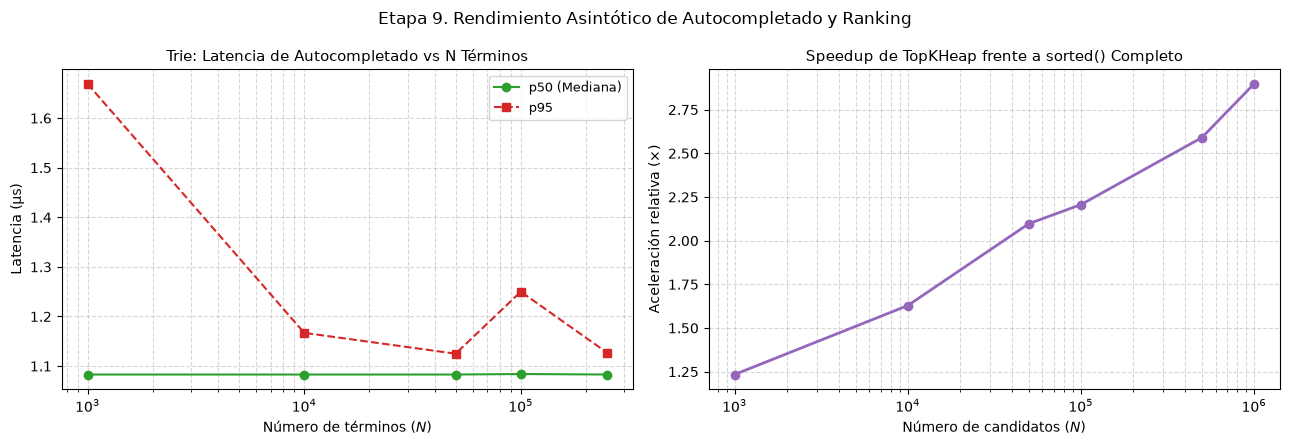

In [10]:
# 8.2 Gráficas comparativas
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Trie Latencia vs N
axes[0].plot(df_trie["n_terminos"], df_trie["latencia_p50_us"], "o-", color="#2ca02c", label="p50 (Mediana)")
axes[0].plot(df_trie["n_terminos"], df_trie["latencia_p95_us"], "s--", color="#d62728", label="p95")
axes[0].set_xscale("log")
axes[0].set_title("Trie: Latencia de Autocompletado vs N Términos", fontsize=11)
axes[0].set_xlabel("Número de términos ($N$)", fontsize=10)
axes[0].set_ylabel("Latencia (µs)", fontsize=10)
axes[0].grid(True, which="both", linestyle="--", alpha=0.5)
axes[0].legend(fontsize=9)

# TopK Speedup vs N
axes[1].plot(df_comp["n"], df_comp["speedup_vs_sorted"], "o-", color="#9467bd", linewidth=2)
axes[1].set_xscale("log")
axes[1].set_title("Speedup de TopKHeap frente a sorted() Completo", fontsize=11)
axes[1].set_xlabel("Número de candidatos ($N$)", fontsize=10)
axes[1].set_ylabel("Aceleración relativa (×)", fontsize=10)
axes[1].grid(True, which="both", linestyle="--", alpha=0.5)

fig.suptitle("Etapa 9. Rendimiento Asintótico de Autocompletado y Ranking", fontsize=12)
fig.tight_layout()
plt.show()


## Paso 8b. Auditoría técnica (2026-10-27)

Cambios verificados en esta sección (detalle en `docs/auditoria_etapas_8_9.md`):
1. **Trie radix.** El Trie de un carácter por nodo creaba 7.2 M nodos para el catálogo completo (90 % unarios, 3.5 GB); la compresión radix deja ~0.72 M con la misma semántica.
2. **Autocompletado difuso.** Damerau-Levenshtein (OSA) sobre el Trie con banda de Ukkonen y poda exacta; solo se activa si la búsqueda exacta no llena $k$.
3. **Búsqueda por índice invertido.** La búsqueda anterior puntuaba $0.5 + 0.5 \cdot S_{pr}$ (relevancia constante) y completaba con el prefijo `query[:3]`.
4. **Calibración del scoring.** Partición temporal 80/20 de órdenes; ver `results/etapa_9/calibracion_scoring*.csv`.


In [11]:
# 8b.1 Tamaño del Trie radix y del índice invertido sobre el catálogo completo
print(f"Términos en el Trie:        {len(servicio.trie):,}")
print(f"Nodos del Trie radix:       {servicio.trie.n_nodos:,}")
print(f"Productos en el índice:     {servicio.indice.n_docs:,}")
print(f"Vocabulario / postings:     {len(servicio.indice.vocabulario):,} / {len(servicio.indice.postings):,}")

# 8b.2 Autocompletado exacto frente a difuso (d = 1)
for consulta in ["stapel", "brotehr", "pilto g2", "scoth tape"]:
    exactas = servicio.trie.autocompletar(consulta, k=3)
    difusas = servicio.autocompletar(consulta, k=3)
    print(f"{consulta!r:14s} exactas={len(exactas)} difusas={[(s['termino'], s.get('distancia', 0)) for s in difusas]}")

display(pd.read_csv(DIR_RESULTADOS / "difuso_trie.csv"))


Términos en el Trie:        585,983
Nodos del Trie radix:       831,377
Productos en el índice:     710,468
Vocabulario / postings:     336,422 / 11,839,094
'stapel'       exactas=0 difusas=[('STAPENS', 1), ('STAPLES', 1), ('Stapex', 1)]
'brotehr'      exactas=0 difusas=[('BROTHER', 1), ('Brother', 1), ('Brother International Corp.', 1)]
'pilto g2'     exactas=0 difusas=[('PILOT G2 Premium Refillable', 1), ('Pilot, G2 Premium Gel', 1), ('Pilot, G2 Gel Ink', 1)]
'scoth tape'   exactas=0 difusas=[('Scotch Tape Dispenser in', 1), ('Scotch Tape Runner Refill.31', 1), ('SCOTCH TAPE TRANSPARENT CRYSTAL', 1)]


,max_dist,consultas,terminos,nodos_radix,latencia_p50_us,latencia_p95_us,latencia_p99_us,acierto_prefijo_original_top5,consultas_sin_resultado_exacto
0,1,300,292300,375715,431.729004,684.748206,791.730917,0.896667,0.940000
1,2,300,292300,375715,1934.271000,3018.218101,3962.910415,0.946667,0.956667


In [12]:
# 8b.3 Búsqueda con corrección ortográfica por token
for consulta in ["toner brother", "toner brtoher", "stapler swinglien"]:
    print(f"{consulta!r} -> {' '.join(servicio.corregir_consulta(consulta))!r}")
    display(pd.DataFrame(servicio.buscar(consulta, k=5))[["rango", "score", "titulo", "tienda"]])


'toner brother' -> 'toner brother'


,rango,score,titulo,tienda
0,1,1.0000,TN436 ColorKing Compatible Toner Cartridge Rep...,Colorking
1,2,0.9526,ColorKing Compatible Toner Cartridge Replaceme...,Colorking
2,3,0.9442,GOTOBY TN760 Toner Cartridge Replacement Compa...,GOTOBY
3,4,0.9412,MCYCOLOR DR730 Drum Unit Compatible Replacemen...,MCYCOLOR
4,5,0.9358,Brother Genuine Cartridge TN760 High Yield Bla...,Brother


'toner brtoher' -> 'toner brother'


,rango,score,titulo,tienda
0,1,1.0000,TN436 ColorKing Compatible Toner Cartridge Rep...,Colorking
1,2,0.9526,ColorKing Compatible Toner Cartridge Replaceme...,Colorking
2,3,0.9442,GOTOBY TN760 Toner Cartridge Replacement Compa...,GOTOBY
3,4,0.9412,MCYCOLOR DR730 Drum Unit Compatible Replacemen...,MCYCOLOR
4,5,0.9358,Brother Genuine Cartridge TN760 High Yield Bla...,Brother


'stapler swinglien' -> 'stapler swingline'


,rango,score,titulo,tienda
0,1,0.9489,"Swingline Stapler, 747 Iconic Desktop Stapler,...",Swingline
1,2,0.9389,"Swingline Stapler, 6 Pack, Desktop Stapler, 25...",Swingline
2,3,0.9370,"Swingline Mini Stapler, Tot, 12 Sheet Capacity...",Swingline
3,4,0.9349,"Swingline Stapler, 747 Classic Desktop Stapler...",Swingline
4,5,0.9263,"Swingline Stapler, 20 Sheet Capacity, Light Du...",Swingline


In [13]:
# 8b.4 Calibración temporal del scoring híbrido (prueba, Recall@10 por grupo de co-compras del ancla)
cal = pd.read_csv(DIR_RESULTADOS / "calibracion_scoring.csv")
prueba = cal[cal["conjunto"] == "prueba"]
display(prueba.pivot_table(index=["relacionados", "normalizacion_pr", "kappa"],
                           columns="grupo", values="recall@10").round(4))
display(pd.read_csv(DIR_RESULTADOS / "calibracion_lineas_base.csv"))
print(json.dumps(json.loads((DIR_RESULTADOS / "calibracion_scoring_resumen.json").read_text()), indent=2))

servicio.cerrar()


grupo                                   3-9    >=10  cold_start    n<=2
relacionados normalizacion_pr kappa                                    
fuga         log              0.0    0.2236  0.1851      0.0644  0.2421
                              1.0    0.2213  0.1845      0.0644  0.2386
                              2.0    0.2198  0.1843      0.0644  0.2369
                              5.0    0.2194  0.1833      0.0644  0.2349
                              10.0   0.2226  0.1817      0.0644  0.2366
...                                     ...     ...         ...     ...
temporal     percentil        2.0    0.0791  0.1776      0.0001  0.0249
                              5.0    0.0784  0.1765      0.0001  0.0247
                              10.0   0.0780  0.1744      0.0001  0.0243
                              20.0   0.0767  0.1710      0.0001  0.0241
                              50.0   0.0753  0.1652      0.0001  0.0238

[63 rows x 4 columns]

,relacionados,modelo,pesos,recall@10,ndcg@10,cobertura_catalogo@10,gini_recomendaciones,pares_entrenamiento,tasa_positivos
0,fuga,solo_similitud,"[1.0, 0.0, 0.0, 0.0]",0.042025,0.026779,0.743853,0.389142,NaN,NaN
1,fuga,solo_relacionados,"[0.0, 1.0, 0.0, 0.0]",0.261392,0.239526,0.679299,0.381731,NaN,NaN
2,fuga,solo_pagerank,"[0.0, 0.0, 1.0, 0.0]",0.193863,0.194438,0.556678,0.546133,NaN,NaN
3,fuga,solo_cocompra,"[0.0, 0.0, 0.0, 1.0]",0.131522,0.133171,0.705342,0.445033,NaN,NaN
4,fuga,hibrido_estatico_log,"[0.35, 0.25, 0.2, 0.2]",0.158317,0.155904,0.616299,0.510989,NaN,NaN
5,fuga,logistica_libre,"[-117.6061, 40.5925, 5.9015, -1.5036]",0.273240,0.265806,0.628064,0.478761,411490.0,0.086877
6,fuga,logistica_no_negativa,"[0.0, 0.8985, 0.1015, 0.0]",0.249905,0.239754,0.619471,0.488201,411490.0,0.086877
7,temporal,solo_similitud,"[1.0, 0.0, 0.0, 0.0]",0.009864,0.006757,0.755161,0.388526,NaN,NaN
8,temporal,solo_relacionados,"[0.0, 1.0, 0.0, 0.0]",0.030803,0.037290,0.716160,0.380346,NaN,NaN
9,temporal,solo_pagerank,"[0.0, 0.0, 1.0, 0.0]",0.097468,0.124712,0.597862,0.532952,NaN,NaN


{
  "fuga": {
    "mejor_kappa": 0.0,
    "mejor_normalizacion": "percentil"
  },
  "temporal": {
    "mejor_kappa": 0.0,
    "mejor_normalizacion": "log"
  },
  "sin": {
    "mejor_kappa": 0.0,
    "mejor_normalizacion": "log"
  },
  "regla_adopcion": {
    "pesos_candidatos": [
      0.0,
      0.0,
      0.9271,
      0.0729
    ],
    "mejora_recall": 0.04622587438901804,
    "mejora_ndcg": 0.10148778462641861,
    "caida_cobertura": 0.07061423235621955,
    "adoptar": false
  },
  "h3_cold_start_identico": true,
  "cobertura_candidatos": 0.6340343082396566,
  "productos_relacionados_temporales": 65248,
  "anclas": 59869,
  "segundos": 296.61742104200675
}


## Resumen del Pipeline Punta a Punta (Etapas 0 a 9)

| Etapa | Responsabilidad | Estructura Principal | Complejidad | Salida Principal hacia Etapa 9 |
| --- | --- | --- | --- | --- |
| **0** | Ingesta & Buffer | ColaCircular con drop | $O(1)$ | Buffer de eventos de transacciones |
| **1** | Preprocesamiento | Merge Sort + Búsqueda Binaria | $O(N \log N)$ | Normalización y validación de tipos |
| **2** | Priorización | MinHeap con envejecimiento (aging) | $O(\log N)$ | Ordenamiento por urgencia y alertas |
| **3** | Almacenamiento | TablaHash + AlmacenCatalogo + CSR | $O(1)$ / $O(nnz)$ | Catálogo en disco y matriz usuario-producto |
| **4** | Indexación | B+Tree en memoria y disco | $O(\log_B N)$ | Búsquedas por rango de precios |
| **5** | Índice Espacial | KD-Tree & KNN exacto | $O(\log N)$ / $O(N d)$ | Línea base exacta de vecinos por atributos |
| **6** | Filtrado Probabilístico | Bloom Filter + Count-Min Sketch | $O(k)$ / $O(d)$ | 47 710 alertas y 31 994 órdenes bloqueadas |
| **7** | Similitud Aproximada | MinHash + LSH & HNSW | $O(b+c)$ / $O(\log N)$ | Similares (atributos) y Relacionados (Jaccard) |
| **8** | Grafo de Dominio | PageRank (Power Iteration) & Louvain | $O(k (\|V\| + \|E\|))$ / $O(N \log N)$ | Autoridad global (PageRank) y comunidades conexas |
| **9** | Servicio & Visualización | Trie radix con Top-K Caché (+ difuso OSA), índice invertido & TopKHeap | $O(L + k)$ consulta, $O(L + hM)$ inserción / $O(N \log K)$ | Autocompletado, búsqueda, ranking Top-K y dashboard web |

## Referencias

- **Cormen, T. H., Leiserson, C. E., Rivest, R. L., & Stein, C. (2009).** *Introduction to Algorithms* (3rd ed.). MIT Press. Cap. 6 (Heapsort y colas de prioridad).
- **Fredkin, E. (1960).** Trie memory. *Communications of the ACM*, 3(9), 490-499. https://doi.org/10.1145/367390.367400
- **Knuth, D. E. (1998).** *The Art of Computer Programming, Volume 3: Sorting and Searching* (2nd ed.). Addison-Wesley. Cap. 6.3 (Digital Searching).
- **Manning, C. D., Raghavan, P., & Schütze, H. (2008).** *Introduction to Information Retrieval*. Cambridge University Press. Cap. 3 (Dictionaries and tolerant retrieval).
